In [79]:
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt 
import seaborn as sns 
from datetime import datetime
import uuid
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import ttest_ind

In [80]:
disease_map = {
    "Common Cold": {
        "Severity": 1,
        "Category": "General",
        "Department": "General"
    },
    "Headache": {
        "Severity": 1,
        "Category": "Neurological",
        "Department": "General"
    },
    "Flu": {
        "Severity": 1,
        "Category": "Infectious",
        "Department": "General"
    },

    "Malaria": {
        "Severity": 3,
        "Category": "Infectious",
        "Department": "General"
    },
    "Typhoid": {
        "Severity": 3,
        "Category": "Infectious",
        "Department": "General"
    },
    "Hepatitis": {
        "Severity": 3,
        "Category": "Infectious",
        "Department": "General"
    },
    "Chickenpox": {
        "Severity": 3,
        "Category": "Infectious",
        "Department": "Pediatrics"
    },
    "Measles": {
        "Severity": 3,
        "Category": "Infectious",
        "Department": "Pediatrics"
    },

    "Hypertension": {
        "Severity": 2,
        "Category": "Chronic",
        "Department": "Cardiology"
    },
    "Diabetes": {
        "Severity": 2,
        "Category": "Chronic",
        "Department": "General"
    },
    "Ulcer": {
        "Severity": 2,
        "Category": "Gastrointestinal",
        "Department": "General"
    },
    "Kidney Disease": {
        "Severity": 4,
        "Category": "Chronic",
        "Department": "Nephrology"
    },

    "Asthma": {
        "Severity": 4,
        "Category": "Respiratory",
        "Department": "General"
    },
    "Pneumonia": {
        "Severity": 4,
        "Category": "Respiratory",
        "Department": "General"
    },

    "Migraine": {
        "Severity": 2,
        "Category": "Neurological",
        "Department": "Neurology"
    },
    "Stroke": {
        "Severity": 5,
        "Category": "Neurological",
        "Department": "Neurology"
    },

    "Appendicitis": {
        "Severity": 5,
        "Category": "Surgical",
        "Department": "Surgery"
    },
    "Fracture": {
        "Severity": 4,
        "Category": "Orthopedic",
        "Department": "Orthopedics"
    },

    "Heart Attack": {
        "Severity": 5,
        "Category": "Cardiac",
        "Department": "Cardiology"
    },

    "Hypertensive Crisis": {
        "Severity": 5,
        "Category": "Cardiac",
        "Department": "Cardiology"
    },

    "Cancer": {
        "Severity": 4,
        "Category": "Oncology",
        "Department": "Oncology"
    },

    "Neonatal Jaundice": {
        "Severity": 4,
        "Category": "Pediatric",
        "Department": "Pediatrics"
    }
}

In [81]:
def generate_patient_data(n=10000, disease_map=None):

    data = []

    days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]

    for _ in range(n):

        # -----------------------------
        # Disease Intelligence Layer
        # -----------------------------
        disease = random.choice(list(disease_map.keys()))

        info = disease_map[disease]

        severity = info["Severity"]
        category = info["Category"]
        department = info["Department"]

        # -----------------------------
        # Demographics
        # -----------------------------
        age = random.randint(1, 90)
        gender = random.choice(["Male", "Female"])

        # -----------------------------
        # Time Features
        # -----------------------------
        day_of_week = random.choice(days)
        hour = random.randint(6, 22)
        is_weekend = int(day_of_week in ["Saturday", "Sunday"])

        appointment_type = random.choice(["walk-in", "booked"])
        arrival_mode = random.choice(["walk-in", "ambulance", "referral"])

        # -----------------------------
        # Hospital Load Simulation
        # -----------------------------
        base_load = {
            "General": (10, 30),
            "Cardiology": (5, 15),
            "Neurology": (5, 12),
            "Orthopedics": (8, 18),
            "Surgery": (3, 10),
            "Pediatrics": (8, 20),
            "Nephrology": (5, 12),
            "Oncology": (5, 12)
        }

        queue_min, queue_max = base_load.get(department, (5, 15))

        queue_length = random.randint(queue_min, queue_max)

        doctor_available = random.randint(1, 5)

        emergency_cases = random.randint(0, 5)

        consultation_duration = random.randint(10, 60)

        hospital_occupancy = random.randint(40, 95)

        doctor_utilization = round(
            queue_length / max(doctor_available, 1),
            2
        )

        # -----------------------------
        # Priority + Queue Position
        # -----------------------------
        if severity == 5:
            priority_level = "Emergency"
            queue_position = 0

        elif severity == 4:
            priority_level = "Urgent"
            queue_position = random.randint(1, 3)

        else:
            priority_level = "Standard"
            queue_position = random.randint(1, queue_length)

        # -----------------------------
        # Waiting Time Engine (REALISTIC MODEL)
        # -----------------------------
        if priority_level == "Emergency":

            waiting_time = np.random.normal(loc=3, scale=1)

        else:

            waiting_time = (
                queue_position * consultation_duration
            ) / max(doctor_available, 1)

            waiting_time += emergency_cases * 2

            if 8 <= hour <= 16:
                waiting_time += 10

            if hospital_occupancy > 80:
                waiting_time += 5

            if appointment_type == "booked":
                waiting_time *= 0.8

            waiting_time += np.random.normal(0, 3)

        waiting_time = max(1, round(waiting_time))

        # -----------------------------
        # Record Row
        # -----------------------------
        data.append([
            age,
            gender,
            disease,
            category,
            severity,
            department,
            priority_level,
            queue_length,
            queue_position,
            doctor_available,
            doctor_utilization,
            emergency_cases,
            consultation_duration,
            hospital_occupancy,
            day_of_week,
            hour,
            is_weekend,
            appointment_type,
            arrival_mode,
            waiting_time
        ])

    # -----------------------------
    # Column Names
    # -----------------------------
    columns = [
        "Age",
        "Gender",
        "Disease",
        "Category",
        "Severity",
        "Department",
        "Priority_Level",
        "Queue_Length",
        "Queue_Position",
        "Doctor_Available",
        "Doctor_Utilization",
        "Emergency_Cases",
        "Consultation_Duration",
        "Hospital_Occupancy",
        "Day_of_Week",
        "Hour",
        "Is_Weekend",
        "Appointment_Type",
        "Arrival_Mode",
        "Waiting_Time"
    ]

    return pd.DataFrame(data, columns=columns)

In [82]:
df = generate_patient_data(
    n=10000,
    disease_map=disease_map
)

print(df.head())

   Age  Gender   Disease          Category  Severity   Department  \
0   34  Female  Fracture        Orthopedic         4  Orthopedics   
1   78  Female     Ulcer  Gastrointestinal         2      General   
2   56    Male   Measles        Infectious         3   Pediatrics   
3   81  Female  Migraine      Neurological         2    Neurology   
4   60    Male   Typhoid        Infectious         3      General   

  Priority_Level  Queue_Length  Queue_Position  Doctor_Available  \
0         Urgent            15               3                 1   
1       Standard            19               4                 2   
2       Standard            18              12                 2   
3       Standard            11               7                 5   
4       Standard            19               6                 2   

   Doctor_Utilization  Emergency_Cases  Consultation_Duration  \
0                15.0                4                     10   
1                 9.5                3        

In [83]:
df.head()

,Age,Gender,Disease,Category,Severity,Department,Priority_Level,Queue_Length,Queue_Position,Doctor_Available,Doctor_Utilization,Emergency_Cases,Consultation_Duration,Hospital_Occupancy,Day_of_Week,Hour,Is_Weekend,Appointment_Type,Arrival_Mode,Waiting_Time
0,34,Female,Fracture,Orthopedic,4,Orthopedics,Urgent,15,3,1,15.0,4,10,94,Tuesday,20,0,booked,ambulance,37
1,78,Female,Ulcer,Gastrointestinal,2,General,Standard,19,4,2,9.5,3,59,95,Thursday,14,0,booked,ambulance,114
2,56,Male,Measles,Infectious,3,Pediatrics,Standard,18,12,2,9.0,1,26,56,Monday,18,0,booked,ambulance,124
3,81,Female,Migraine,Neurological,2,Neurology,Standard,11,7,5,2.2,1,35,43,Monday,16,0,walk-in,ambulance,60
4,60,Male,Typhoid,Infectious,3,General,Standard,19,6,2,9.5,1,39,82,Tuesday,15,0,booked,referral,107


In [84]:
df.isnull().sum()

Age                      0
Gender                   0
Disease                  0
Category                 0
Severity                 0
Department               0
Priority_Level           0
Queue_Length             0
Queue_Position           0
Doctor_Available         0
Doctor_Utilization       0
Emergency_Cases          0
Consultation_Duration    0
Hospital_Occupancy       0
Day_of_Week              0
Hour                     0
Is_Weekend               0
Appointment_Type         0
Arrival_Mode             0
Waiting_Time             0
dtype: int64

In [85]:
df.describe()

,Age,Severity,Queue_Length,Queue_Position,Doctor_Available,Doctor_Utilization,Emergency_Cases,Consultation_Duration,Hospital_Occupancy,Hour,Is_Weekend,Waiting_Time
count,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.0,10000.000000
mean,46.041900,3.182000,14.794800,5.48650,3.015400,6.718318,2.52680,35.124600,67.280700,13.989800,0.0,87.937400
std,25.946982,1.306693,6.894828,6.13423,1.415331,5.699768,1.71621,14.792564,16.095528,4.872973,0.0,133.324536
min,1.000000,1.000000,3.000000,0.00000,1.000000,0.600000,0.00000,10.000000,40.000000,6.000000,0.0,1.000000
25%,24.000000,2.000000,10.000000,1.00000,2.000000,3.000000,1.00000,22.000000,53.000000,10.000000,0.0,17.000000
50%,47.000000,3.000000,13.000000,3.00000,3.000000,5.000000,3.00000,35.000000,67.000000,14.000000,0.0,43.000000
75%,68.000000,4.000000,19.000000,8.00000,4.000000,8.500000,4.00000,48.000000,81.000000,18.000000,0.0,104.000000
max,90.000000,5.000000,30.000000,30.00000,5.000000,30.000000,5.00000,60.000000,95.000000,22.000000,0.0,1753.000000


In [86]:
df.shape

(10000, 20)

In [87]:
df.dtypes

Age                        int64
Gender                       str
Disease                      str
Category                     str
Severity                   int64
Department                   str
Priority_Level               str
Queue_Length               int64
Queue_Position             int64
Doctor_Available           int64
Doctor_Utilization       float64
Emergency_Cases            int64
Consultation_Duration      int64
Hospital_Occupancy         int64
Day_of_Week                  str
Hour                       int64
Is_Weekend                 int64
Appointment_Type             str
Arrival_Mode                 str
Waiting_Time               int64
dtype: object

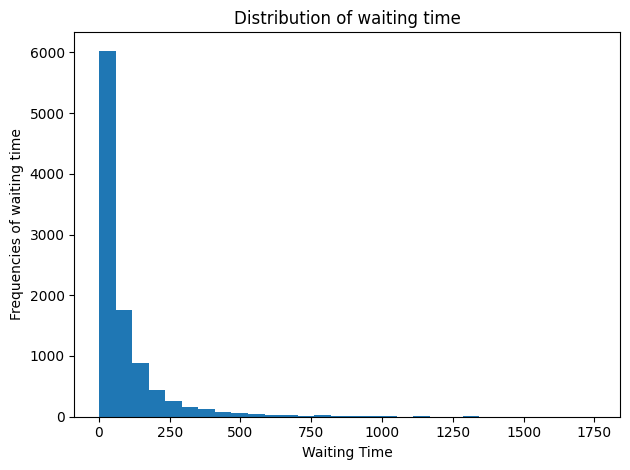

In [88]:
plt.hist(df['Waiting_Time'], bins=30)
plt.xlabel('Waiting Time')
plt.ylabel('Frequencies of waiting time')
plt.title('Distribution of waiting time')
plt.tight_layout()

Text(0, 0.5, 'Waiting Time')

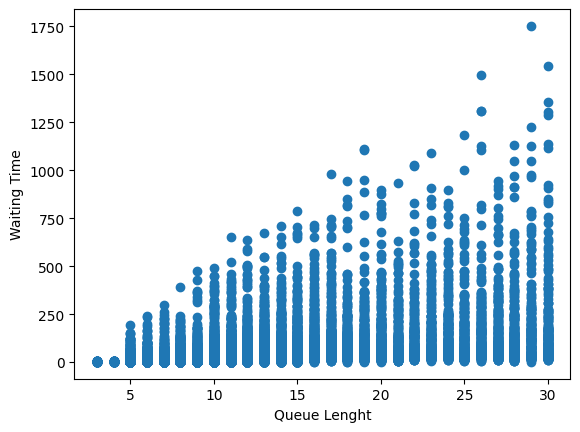

In [89]:
plt.scatter(
    df['Queue_Length'],
    df['Waiting_Time']
)
plt.xlabel('Queue Lenght')
plt.ylabel('Waiting Time')

In [90]:
numeric_df=df.select_dtypes(include=['int64', 'float64'])
corr= numeric_df.corr()

<Axes: >

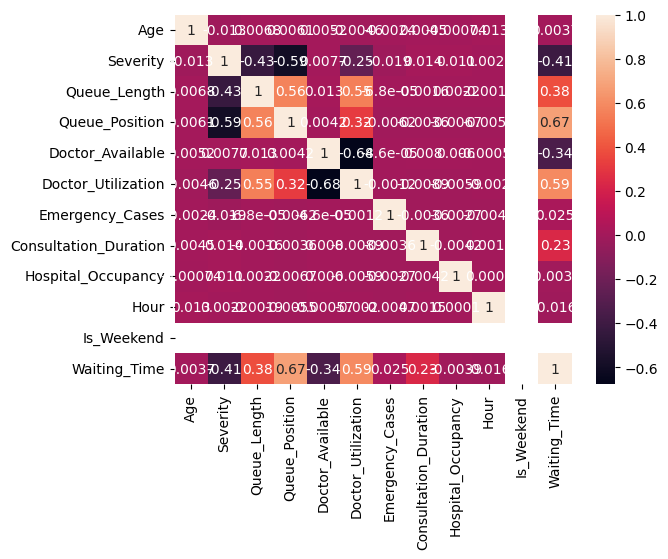

In [91]:
sns.heatmap(
    corr,
    annot=True
)

In [92]:
appointment_waiting_time=df.groupby('Appointment_Type')['Waiting_Time'].mean()
appointment_waiting_time

Appointment_Type
booked     77.154924
walk-in    98.702638
Name: Waiting_Time, dtype: float64

In [93]:
df.groupby('Department')['Waiting_Time'].mean().sort_values(ascending = True)

Department
Surgery          2.997758
Cardiology      32.383505
Oncology        35.846154
Nephrology      37.725728
Orthopedics     39.311751
Neurology       39.454645
Pediatrics      95.487699
General        135.462148
Name: Waiting_Time, dtype: float64

In [94]:
df.groupby(
    "Severity"
)["Waiting_Time"].mean()

Severity
1    159.070423
2    126.583691
3    141.154418
4     38.369084
5      2.993089
Name: Waiting_Time, dtype: float64

In [95]:
df.groupby(
    "Disease"
)["Waiting_Time"].mean().sort_values()

Disease
Hypertensive Crisis      2.937630
Appendicitis             2.997758
Stroke                   3.006424
Heart Attack             3.030801
Cancer                  35.846154
Asthma                  37.471264
Kidney Disease          37.725728
Fracture                39.311751
Neonatal Jaundice       39.414097
Pneumonia               40.209302
Migraine                77.448661
Hypertension            90.819302
Chickenpox             119.623158
Measles                126.377483
Flu                    149.655889
Hepatitis              150.842697
Typhoid                153.295983
Malaria                156.761364
Common Cold            158.935841
Ulcer                  161.383795
Headache               167.987069
Diabetes               176.819565
Name: Waiting_Time, dtype: float64

In [96]:

walkin = df[
    df["Appointment_Type"]=="walk-in"
]["Waiting_Time"]

booked = df[
    df["Appointment_Type"]=="booked"
]["Waiting_Time"]

ttest_ind(walkin, booked)

TtestResult(statistic=np.float64(8.107035216361243), pvalue=np.float64(5.794723629999233e-16), df=np.float64(9998.0))

In [97]:
X = df.drop("Waiting_Time", axis=1)

y = df["Waiting_Time"]

In [98]:
from sklearn.preprocessing import LabelEncoder

encoders = {}

categorical_cols = X.select_dtypes(
    include='object'
).columns

for col in categorical_cols:

    le = LabelEncoder()

    X[col] = le.fit_transform(X[col])

    encoders[col] = le

C:\Users\ICTM-NET LAB 11\AppData\Local\Temp\ipykernel_1160\651214290.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(


In [99]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [100]:

model = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [101]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

predictions = model.predict(X_test)

mae = mean_absolute_error(
    y_test,
    predictions
)

mse = mean_squared_error(
    y_test,
    predictions
)

rmse = np.sqrt(mse)

r2 = r2_score(
    y_test,
    predictions
)

print(f"MAE : {mae:.2f}")
print(f"MSE : {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²  : {r2:.4f}")

MAE : 8.32
MSE : 266.32
RMSE: 16.32
R²  : 0.9860


In [102]:

importance = pd.DataFrame({

    "Feature": X.columns,

    "Importance": model.feature_importances_

})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

print(importance.head(15))

                  Feature  Importance
8          Queue_Position    0.481988
9        Doctor_Available    0.211415
12  Consultation_Duration    0.178220
10     Doctor_Utilization    0.101557
17       Appointment_Type    0.008092
7            Queue_Length    0.002610
4                Severity    0.002384
6          Priority_Level    0.002332
13     Hospital_Occupancy    0.002083
0                     Age    0.002020
15                   Hour    0.001778
11        Emergency_Cases    0.001429
2                 Disease    0.001101
3                Category    0.000985
14            Day_of_Week    0.000931


In [103]:
import joblib

joblib.dump(
    model,
    "hospital_model.pkl"
)

joblib.dump(
    encoders,
    "encoders.pkl"
)

['encoders.pkl']

In [104]:
import pandas as pd
import joblib


# ==========================================
# Priority Logic
# ==========================================

def get_priority_level(severity):

    if severity == 5:
        return "Emergency"

    elif severity == 4:
        return "Urgent"

    else:
        return "Standard"


# ==========================================
# Prediction Engine
# ==========================================

def predict_patient_outcome(
    model,
    encoders,
    patient_input,
    training_columns
):

    # ----------------------------------
    # Auto-generate derived features
    # ----------------------------------

    patient_input["Priority_Level"] = get_priority_level(
        patient_input["Severity"]
    )

    patient_input["Doctor_Utilization"] = round(
        patient_input["Queue_Length"] /
        max(patient_input["Doctor_Available"], 1),
        2
    )

    patient_input["Is_Weekend"] = int(
        patient_input["Day_of_Week"]
        in ["Saturday", "Sunday"]
    )

    # ----------------------------------
    # Convert to DataFrame
    # ----------------------------------

    df = pd.DataFrame([patient_input])

    # ----------------------------------
    # Encode categorical columns
    # ----------------------------------

    categorical_cols = [

        "Gender",
        "Disease",
        "Category",
        "Department",
        "Priority_Level",
        "Day_of_Week",
        "Appointment_Type",
        "Arrival_Mode"

    ]

    for col in categorical_cols:

        if col in df.columns and col in encoders:

            le = encoders[col]

            value = df[col].iloc[0]

            if value in le.classes_:

                df[col] = le.transform(df[col])

            else:

                # Unknown category fallback
                df[col] = -1

    # ----------------------------------
    # Match training columns exactly
    # ----------------------------------

    df = df.reindex(
        columns=training_columns,
        fill_value=0
    )

    # ----------------------------------
    # Predict waiting time
    # ----------------------------------

    predicted_wait = model.predict(df)[0]

    severity = patient_input["Severity"]

    # ----------------------------------
    # Emergency Override
    # ----------------------------------

    if severity == 5:

        predicted_wait = min(
            predicted_wait,
            5
        )

        urgency = "EMERGENCY"

        recommendation = (
            "Proceed immediately to the Emergency Unit."
        )

    elif predicted_wait <= 15:

        urgency = "LOW"

        recommendation = (
            "Appointment slot is favorable."
        )

    elif predicted_wait <= 40:

        urgency = "MEDIUM"

        recommendation = (
            "Moderate congestion expected."
        )

    else:

        urgency = "HIGH"

        recommendation = (
            "High congestion expected. Consider an alternative appointment slot."
        )

    # ----------------------------------
    # Return Prediction
    # ----------------------------------

    return {

        "Predicted_Waiting_Time_Minutes":
            round(float(predicted_wait), 2),

        "Urgency_Level":
            urgency,

        "Priority_Level":
            patient_input["Priority_Level"],

        "Recommendation":
            recommendation

    }

In [105]:
training_columns = X.columns.tolist()

sample_patient = {

    "Age": 45,
    "Gender": "Male",

    "Disease": "Malaria",

    "Category": "Infectious",

    "Severity": 3,

    "Department": "General",

    "Queue_Length": 18,

    "Queue_Position": 7,

    "Doctor_Available": 3,

    "Emergency_Cases": 2,

    "Consultation_Duration": 15,

    "Hospital_Occupancy": 75,

    "Day_of_Week": "Monday",

    "Hour": 10,

    "Appointment_Type": "booked",

    "Arrival_Mode": "walk-in"
}

result = predict_patient_outcome(
    model=rf_model,
    encoders=encoders,
    patient_input=sample_patient,
    training_columns=training_columns
)

print(result)

{'Predicted_Waiting_Time_Minutes': 38.62, 'Urgency_Level': 'MEDIUM', 'Priority_Level': 'Standard', 'Recommendation': 'Moderate congestion expected.'}


In [106]:
def get_priority_level(severity):

    if severity == 5:
        return "Emergency"
    elif severity == 4:
        return "Urgent"
    return "Standard"


def build_features(patient_input):

    features = patient_input.copy()

    # Priority
    features["Priority_Level"] = get_priority_level(
        features["Severity"]
    )

    # Utilization
    features["Doctor_Utilization"] = (
        features["Queue_Length"] /
        max(features["Doctor_Available"], 1)
    )

    # Weekend flag
    features["Is_Weekend"] = int(
        features["Day_of_Week"] in ["Saturday", "Sunday"]
    )

    return features

In [107]:


def predict_wait_time(model, encoders, training_columns, patient_input):

    df = pd.DataFrame([patient_input])

    # Encode categorical variables
    for col, le in encoders.items():

        if col in df.columns:

            val = df[col].iloc[0]

            if val in le.classes_:
                df[col] = le.transform([val])
            else:
                df[col] = -1

    # Align with training columns
    df = df.reindex(columns=training_columns, fill_value=0)

    # Predict
    wait_time = model.predict(df)[0]

    return float(wait_time)

In [108]:
from datetime import datetime, timedelta
import uuid



def schedule_appointment(
    patient_input,
    model,
    encoders,
    training_columns,
    available_doctors,
    hospital_slots
):

    # ------------------------
    # Booking ID
    # ------------------------
    booking_id = "HSP-" + str(uuid.uuid4()).split("-")[0].upper()

    # ------------------------
    # Disease Info
    # ------------------------
    disease_info = disease_map[patient_input["Disease"]]

    severity = disease_info["Severity"]
    department = disease_info["Department"]

    # ------------------------
    # Emergency Handling
    # ------------------------
    if severity == 5:

        doctor = available_doctors[department][0]

        return {
            "Booking_ID": booking_id,
            "Status": "EMERGENCY",
            "Assigned_Doctor": doctor["Name"],
            "Department": department,
            "Slot": "IMMEDIATE",
            "Queue_Position": 0,
            "Recommended_Action": "Go to Emergency Unit Immediately"
        }

    # ------------------------
    # Normal Scheduling
    # ------------------------
    best_slot = None
    best_wait = float("inf")

    for slot in hospital_slots:

        queue_position = slot["current_queue"] + 1

        doctor = available_doctors[department][
            slot["doctor_index"] % len(available_doctors[department])
        ]

        # Build feature input
        features = patient_input.copy()
        features["Queue_Position"] = queue_position
        features["Hospital_Occupancy"] = slot["occupancy"]
        features["Doctor_Available"] = len(available_doctors[department])

        # -------- FEATURE ENGINE --------
        from_feature_engine = build_features(features)

        # -------- PREDICTION --------
        wait_time = predict_wait_time(
            model,
            encoders,
            training_columns,
            from_feature_engine
        )

        if wait_time < best_wait:

            best_wait = wait_time

            best_slot = {
                "slot_time": slot["time"],
                "doctor": doctor,
                "queue_position": queue_position
            }

    # ------------------------
    # Final Time Calculation
    # ------------------------
    estimated_time = datetime.now() + timedelta(
        minutes=best_wait
    )

    # ------------------------
    # RESPONSE
    # ------------------------
    return {

        "Booking_ID": booking_id,
        "Status": "CONFIRMED",
        "Department": department,
        "Assigned_Doctor": best_slot["doctor"]["Name"],
        "Doctor_ID": best_slot["doctor"]["ID"],
        "Recommended_Slot": best_slot["slot_time"],
        "Queue_Position": best_slot["queue_position"],
        "Predicted_Wait_Minutes": round(best_wait, 2),
        "Estimated_Arrival_Time": estimated_time.strftime("%H:%M")
    }

In [109]:
from fastapi import FastAPI
from pydantic import BaseModel
import joblib
from datetime import datetime, timedelta
import uuid
import pandas as pd

In [110]:
disease_map = {
    "Common Cold": {"Severity": 1, "Category": "General", "Department": "General"},
    "Headache": {"Severity": 1, "Category": "Neurological", "Department": "General"},
    "Flu": {"Severity": 1, "Category": "Infectious", "Department": "General"},

    "Malaria": {"Severity": 3, "Category": "Infectious", "Department": "General"},
    "Typhoid": {"Severity": 3, "Category": "Infectious", "Department": "General"},
    "Hepatitis": {"Severity": 3, "Category": "Infectious", "Department": "General"},

    "Chickenpox": {"Severity": 3, "Category": "Infectious", "Department": "Pediatrics"},
    "Measles": {"Severity": 3, "Category": "Infectious", "Department": "Pediatrics"},

    "Hypertension": {"Severity": 2, "Category": "Chronic", "Department": "Cardiology"},
    "Diabetes": {"Severity": 2, "Category": "Chronic", "Department": "General"},
    "Ulcer": {"Severity": 2, "Category": "Gastrointestinal", "Department": "General"},
    "Kidney Disease": {"Severity": 4, "Category": "Chronic", "Department": "Nephrology"},

    "Asthma": {"Severity": 4, "Category": "Respiratory", "Department": "General"},
    "Pneumonia": {"Severity": 4, "Category": "Respiratory", "Department": "General"},

    "Migraine": {"Severity": 2, "Category": "Neurological", "Department": "Neurology"},
    "Stroke": {"Severity": 5, "Category": "Neurological", "Department": "Neurology"},

    "Appendicitis": {"Severity": 5, "Category": "Surgical", "Department": "Surgery"},
    "Fracture": {"Severity": 4, "Category": "Orthopedic", "Department": "Orthopedics"},

    "Heart Attack": {"Severity": 5, "Category": "Cardiac", "Department": "Cardiology"},
    "Hypertensive Crisis": {"Severity": 5, "Category": "Cardiac", "Department": "Cardiology"},

    "Cancer": {"Severity": 4, "Category": "Oncology", "Department": "Oncology"},

    "Neonatal Jaundice": {"Severity": 4, "Category": "Pediatric", "Department": "Pediatrics"}
}

In [111]:
class PatientRequest(BaseModel):
    Age: int
    Gender: str
    Disease: str
    Day_of_Week: str
    Hour: int
    Queue_Length: int
    Doctor_Available: int
    Emergency_Cases: int
    Consultation_Duration: int
    Hospital_Occupancy: int
    Appointment_Type: str

In [112]:
import joblib

joblib.dump(model, "hospital_model.pkl")
joblib.dump(encoders, "encoders.pkl")
joblib.dump(training_columns, "training_columns.pkl")

['training_columns.pkl']

In [117]:
model = joblib.load("hospital_model.pkl")
encoders = joblib.load("encoders.pkl")
training_columns = joblib.load("training_columns.pkl")

In [115]:
import os
print(os.getcwd())
print(os.listdir())

c:\Users\ICTM-NET LAB 11\Desktop\Hospital_booking_and_waiting_time_predictor
['encoders.pkl', 'hospital_booking_and_waiting_time_predictor.ipynb', 'hospital_model.pkl', 'hospital_waiting_time_data.csv', 'patient_waiting_time_model.pkl', 'prototype.ipynb', 'training_columns.pkl', 'waiting_time.ipynb']


In [119]:
def build_features(data):

    info = disease_map[data["Disease"]]

    data["Severity"] = info["Severity"]
    data["Category"] = info["Category"]
    data["Department"] = info["Department"]

    data["Priority_Level"] = (
        "Emergency" if data["Severity"] == 5
        else "Urgent" if data["Severity"] == 4
        else "Standard"
    )

    data["Doctor_Utilization"] = (
        data["Queue_Length"] / max(data["Doctor_Available"], 1)
    )

    data["Is_Weekend"] = int(
        data["Day_of_Week"] in ["Saturday", "Sunday"]
    )

    return data

In [120]:
def predict_wait_time(data):

    df = pd.DataFrame([data])

    for col, le in encoders.items():
        if col in df.columns:
            val = df[col].iloc[0]

            if val in le.classes_:
                df[col] = le.transform([val])
            else:
                df[col] = -1

    df = df.reindex(columns=training_columns, fill_value=0)

    return float(model.predict(df)[0])

In [121]:
app = FastAPI(
    title="Hospital AI Scheduling System",
    version="1.0"
)

In [123]:
@app.post("/predict")
def predict(patient: PatientRequest):

    # -------------------------
    # 1. REQUEST PROCESSING
    # -------------------------
    data = patient.dict()

    # -------------------------
    # 2. FEATURE ENGINEERING
    # -------------------------
    data = build_features(data)

    # -------------------------
    # 3. EMERGENCY SHORT-CIRCUIT
    # -------------------------
    if data["Severity"] == 5:
        booking_id = "HSP-" + str(uuid.uuid4()).split("-")[0].upper()

        return {
            "Booking_ID": booking_id,
            "Status": "EMERGENCY",
            "Department": data["Department"],
            "Priority": "EMERGENCY",
            "Action": "Go to Emergency Unit Immediately"
        }

    # -------------------------
    # 4. ML PREDICTION
    # -------------------------
    wait_time = predict_wait_time(data)

    # -------------------------
    # 5. SMART SCHEDULING ENGINE
    # -------------------------

    now = datetime.now()

    # Prevent congestion (soft cap logic)
    if wait_time < 10:
        wait_time = 10  # minimum realistic hospital delay

    # FCFS adjustment (important improvement)
    queue_factor = data["Queue_Length"] * 2
    doctor_factor = max(data["Doctor_Available"], 1)

    adjusted_wait = (wait_time + queue_factor) / doctor_factor

    # Peak hour penalty
    if 8 <= data["Hour"] <= 16:
        adjusted_wait += 5

    # Booked patients get slight priority advantage
    if data["Appointment_Type"] == "booked":
        adjusted_wait *= 0.85

    # -------------------------
    # 6. FINAL BOOKING TIME
    # -------------------------
    arrival_time = now + timedelta(minutes=adjusted_wait)

    booking_id = "HSP-" + str(uuid.uuid4()).split("-")[0].upper()

    # -------------------------
    # 7. RESPONSE
    # -------------------------
    return {
        "Booking_ID": booking_id,
        "Status": "CONFIRMED",
        "Disease": data["Disease"],
        "Department": data["Department"],
        "Priority": data["Priority_Level"],
        "Raw_Prediction": round(wait_time, 2),
        "Final_Wait_Time": round(adjusted_wait, 2),
        "Estimated_Arrival_Time": arrival_time.strftime("%H:%M")
    }